# Laboratory 3, Part B - Images to numbers

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

Install once if needed: `pip install scikit-learn Pillow numpy pandas matplotlib`

For basic models the pixel values themselves are the features. The engineering here is
**grayscale conversion** (three channels to one) and **flattening** (a 2-D grid to a 1-D vector).

## Task 3.2 - Convert and flatten pixels

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Set image_file_path to a real file to use your own picture; None builds a seeded dummy image.
image_file_path = None

if image_file_path and os.path.exists(image_file_path):
    original_image = Image.open(image_file_path)
    print("Loaded image from file:", image_file_path)
else:
    rng = np.random.default_rng(0)
    dummy = rng.integers(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, "RGB")
    print("No image file given - created a dummy 100x100 RGB image")

original_image = original_image.convert("RGB")
rgb = np.array(original_image)
h, w, ch = rgb.shape
print("RGB shape (H, W, channels):", rgb.shape)
print("Features in the RGB image :", h * w * ch)

No image file given - created a dummy 100x100 RGB image
RGB shape (H, W, channels): (100, 100, 3)
Features in the RGB image : 30000


In [2]:
gray_image = original_image.convert("L")
gray = np.array(gray_image)

print("Grayscale shape (H, W)   :", gray.shape)
print("Features after grayscale :", gray.size)
print("Reduction                :", (h * w * ch) // gray.size, "x fewer features")

Grayscale shape (H, W)   : (100, 100)
Features after grayscale : 10000
Reduction                : 3 x fewer features


In [3]:
vector = gray.flatten()

print("Flattened vector shape:", vector.shape)
print("First 10 values       :", vector[:10])
print("Data type             :", vector.dtype)

Flattened vector shape: (10000,)
First 10 values       : [127 213 104 206 187 155 126  93 157 117]
Data type             : uint8


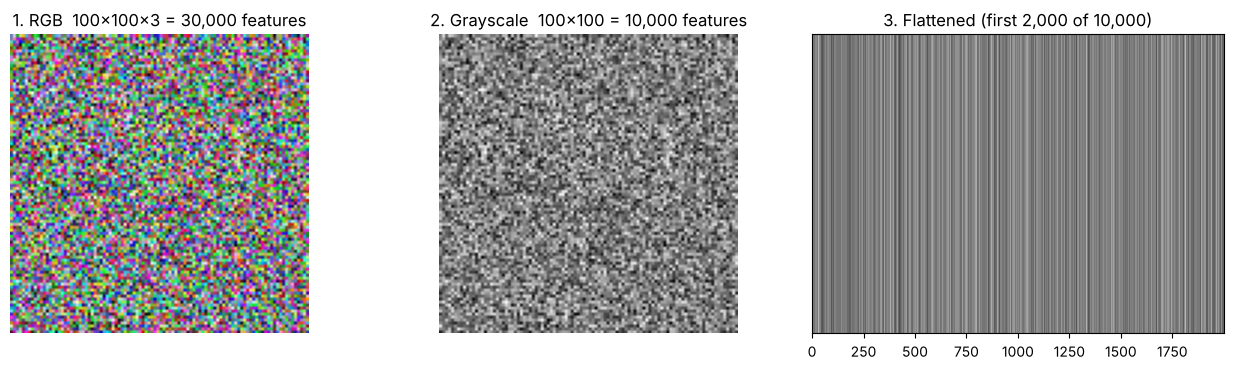

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(original_image)
axes[0].set_title(f"1. RGB  {h}x{w}x{ch} = {h*w*ch:,} features")
axes[1].imshow(gray_image, cmap="gray")
axes[1].set_title(f"2. Grayscale  {h}x{w} = {h*w:,} features")
axes[2].imshow(vector[:2000].reshape(1, -1), cmap="gray", aspect="auto")
axes[2].set_title(f"3. Flattened (first 2,000 of {vector.size:,})")
axes[2].set_yticks([])
for ax in axes[:2]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Discussion questions (Part B)

**1. Grayscale as feature engineering**

Grayscale collapses the three colour channels (R, G, B) into a single brightness value per pixel (Pillow uses a weighted sum, L = 0.299 R + 0.587 G + 0.114 B). That cuts the number of features to a third, which means less memory, faster training and less risk of overfitting. The price is all colour information, so it is a good choice when shape or intensity matters (digits) and a bad one when colour is the clue (ripe vs unripe fruit).

**2. Length of the flattened vector for an H x W image**

H x W. After grayscale each pixel is one number, so a 100 x 100 image gives 10,000 features (the RGB version would have 3 x H x W = 30,000).

**3. Why flatten before Logistic Regression or an SVM?**

Models such as Logistic Regression or an SVM expect every sample to be one row of numbers, an input of shape (n_samples, n_features). An image is a 2-D grid, so it must be unrolled into a 1-D vector first. The cost is that neighbouring-pixel structure is no longer explicit: the model sees 4,096 independent columns. Convolutional networks exist to keep that spatial structure.

**4. Why resize every image to one size first?**

A model has a fixed number of input features, and a matrix X needs equal-length rows. Resizing every image to the same size (for example 64 x 64) guarantees vectors of identical length (4,096), so photos of any original size can be stacked and fed to the same model. Smaller images also cost less memory and compute. The trade-off is lost fine detail, and distortion if the original aspect ratio was not square.

## In-lab exercises

**Exercise 3.** Resize a real photograph to 64x64 and to 32x32. The photograph is `china.jpg`,
one of the sample images that ships inside scikit-learn, so no download is needed.

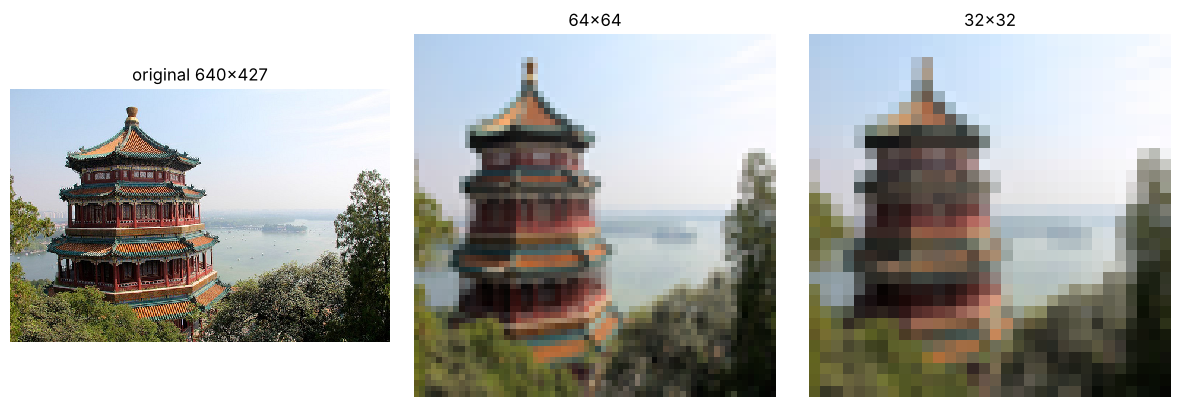

original 640x427: flattened grayscale vector length = 273,280
           64x64: flattened grayscale vector length = 4,096
           32x32: flattened grayscale vector length = 1,024


In [5]:
from sklearn.datasets import load_sample_images

photo = Image.fromarray(load_sample_images().images[0]).convert("RGB")
versions = {
    f"original {photo.size[0]}x{photo.size[1]}": photo,
    "64x64": photo.resize((64, 64)),
    "32x32": photo.resize((32, 32)),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, img) in zip(axes, versions.items()):
    ax.imshow(img, interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

for name, img in versions.items():
    length = len(np.array(img.convert("L")).flatten())
    print(f"{name:>16}: flattened grayscale vector length = {length:,}")

At 64x64 the overall scene and large shapes survive but small details and fine texture
are gone. At 32x32 only coarse blocks of colour and brightness remain, and small objects can no longer be
recognised. Fewer pixels mean a shorter vector but less information.

**Exercise 4.** `image_to_features(path, size)` lives in `image_utils.py` (load, resize,
grayscale, flatten). Check that three differently sized images give vectors of the same length.

In [6]:
from glob import glob
from image_utils import image_to_features

files = [sorted(glob("data/class_a/*.png"))[0], sorted(glob("data/class_b/*.png"))[0],
         sorted(glob("data/class_a/*.png"))[-1]]

lengths = set()
for path in files:
    with Image.open(path) as picture:
        original_size = picture.size
    vec = image_to_features(path, size=(64, 64))
    lengths.add(len(vec))
    print(f"{os.path.basename(path):>14}  original {original_size[0]}x{original_size[1]}  ->  length {len(vec)}")

print()
print("All lengths identical:", len(lengths) == 1)

 circle_01.png  original 137x118  ->  length 4096
 square_01.png  original 116x107  ->  length 4096
 circle_10.png  original 92x130  ->  length 4096

All lengths identical: True


## Home assignment - a 20-image labelled dataset

`make_data.py` generated twenty synthetic images in two classes: **class_a = filled circle
(label 0)**, **class_b = filled square (label 1)**, with different sizes, colours, positions and a
little noise. They are drawn shapes, not photographs.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

SIZE = (64, 64)
folders = {0: "data/class_a", 1: "data/class_b"}

rows, labels = [], []
for label, folder in folders.items():
    for path in sorted(glob(os.path.join(folder, "*.png"))):
        rows.append(image_to_features(path, size=SIZE))
        labels.append(label)

X = np.vstack(rows)
y = np.array(labels)
np.savez("dataset.npz", X=X, y=y)

print("X shape:", X.shape, "  y shape:", y.shape)
print("Feature space dimensionality:", X.shape[1])
print("Samples per feature:", round(X.shape[0] / X.shape[1], 4))
print("Class balance:", dict(zip(*np.unique(y, return_counts=True))))

scaled = X / 255.0
model = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print()
print("Training accuracy      :", round(model.fit(scaled, y).score(scaled, y), 3))
print("5-fold CV accuracy     :", cross_val_score(model, scaled, y, cv=cv).round(2))

X shape: (20, 4096)   y shape: (20,)
Feature space dimensionality: 4096
Samples per feature: 0.0049
Class balance: {np.int64(0): np.int64(10), np.int64(1): np.int64(10)}



Training accuracy      : 1.0


5-fold CV accuracy     : [0.5  0.75 0.75 0.5  0.5 ]


**Is 20 samples in 4,096 dimensions a sound basis for learning?**  Twenty samples in 4,096 dimensions is not a sound basis for learning. There are about 0.005 samples per feature, far fewer samples than features, so many different linear boundaries can separate the training images perfectly and the model cannot tell which one generalises (high variance, overfitting). In very high dimensions distances also become less informative (curse of dimensionality). The cross-validation score printed above uses only 4 test images per fold, so it is a rough guide, not a reliable estimate. In the run above, training accuracy is 1.0 while cross-validation accuracy is only 0.5 to 0.75, which is exactly the overfitting this predicts: the model memorises the 20 images but does not generalise. A real task would need far more images, regularisation, dimensionality reduction (for example PCA) or data augmentation, or a convolutional network that shares weights across the image.